# 04 · Barge-in (interrupting the model) + transcripts

In notebook 03, model audio arrives **faster than real time** and piles up in the speaker buffer. If you talk over the model, two things go wrong:

1. **You keep hearing it**: seconds of queued audio still play, and its answer to your interruption waits behind them.
2. **Its memory is wrong**: the server thinks you heard the whole reply, even though you cut it off.

The fix has two halves, both triggered by `input_audio_buffer.speech_started`:
- **local**: `speaker.clear()` drops the unplayed audio instantly
- **server**: `conversation.item.truncate` with `audio_end_ms` = how much you actually heard

Also new: **user transcripts**. The realtime model never writes down what *you* said, so a side model (`gpt-4o-mini-transcribe`) does it. Watch for `user_said` in the logs.

In [1]:
import asyncio, inspect
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio
from live import audio, realtime

## 1. The session now includes transcription

In [2]:
INSTRUCTIONS = "You are a friendly voice tutor. Keep answers short unless asked for a story."
realtime.session_config(INSTRUCTIONS)['audio']['input']

{'format': {'type': 'audio/pcm', 'rate': 24000},
 'turn_detection': {'type': 'server_vad', 'silence_duration_ms': 500},
 'transcription': {'model': 'gpt-4o-mini-transcribe'}}

## 2. A scripted user who interrupts
Ask for a long story, stay quiet for `GAP_S` seconds while the model talks, then cut in.

In [3]:
q1 = audio.say("Tell me a long story about a dragon.")
q2 = audio.say("Wait, what is two plus two?")
round(len(q1) / audio.RATE, 2), round(len(q2) / audio.RATE, 2)

(2.95, 2.71)

In [4]:
GAP_S = 4.0
script = np.concatenate([q1, np.zeros(int(GAP_S * audio.RATE), np.int16), q2])
interrupt_at = round((len(q1) + GAP_S * audio.RATE) / audio.RATE, 2)
script.shape, round(len(script) / audio.RATE, 2), interrupt_at

((231936,), 9.66, 6.95)

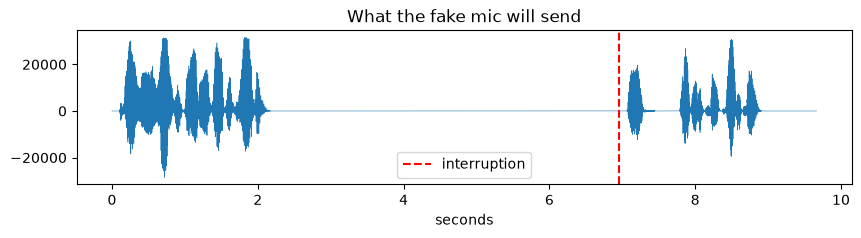

In [5]:
t = np.arange(len(script)) / audio.RATE
plt.figure(figsize=(10, 2)); plt.plot(t, script, lw=0.4); plt.axvline(interrupt_at, color='r', ls='--', label='interruption')
plt.xlabel('seconds'); plt.legend(); plt.title('What the fake mic will send'); plt.show()

In [6]:
spk = audio.Speaker(); spk.stream.start()
RUN_S = len(script) / audio.RATE + 10
RUN_S

19.664

## 3. Run A: barge-in **off** (notebook 03 behaviour)

In [7]:
ws = await realtime.start_session(INSTRUCTIONS)
log_a = await realtime.converse(ws, audio.file_chunks(script), spk, seconds=RUN_S, barge_in=False)
await ws.close()

0.43 input_audio_buffer.speech_started 0.00s of audio still queued


3.27 input_audio_buffer.speech_stopped 2752
3.27 input_audio_buffer.committed 
3.28 response.created in_progress


3.8 first_audio_delta 


4.05 user_said Tell me a long story about a dragon.


7.25 model_said Sure! Once upon a time, in a vast valley surrounded by towering mountains, there lived a gentle dragon named Ember. Ember wasn’t like other dragons—he preferred reading ancient scrolls and helping lost travelers find their way. One day, a young explorer named Lila got caught in a storm, and along came Ember, shielding her from the wind. They soon became friends and set off on adventures together. They journeyed through enchanted forests, climbed crystal mountains, and met wise old owls who shared their knowledge. And so, their tale continued, full of magic and friendship.
7.25 response.done completed


7.72 input_audio_buffer.speech_started 26.75s of audio still queued


10.43 input_audio_buffer.speech_stopped 9504
10.43 input_audio_buffer.committed 
10.43 response.created in_progress


10.74 first_audio_delta 


10.99 user_said Wait, what is two plus two?
11.19 model_said 2 plus 2 is 4. If you have any other math questions, feel free to ask!
11.2 response.done completed


Look at the second `speech_started`: that is how much story was still queued when the user cut in. The reply to the interruption is stuck behind it:

In [8]:
queued_a = [d for _, ev, d in log_a if ev == 'input_audio_buffer.speech_started'][-1]
still_playing_after_run = round(spk.buffered_seconds(), 2)
queued_a, still_playing_after_run

('26.75s of audio still queued', 17.2)

In [9]:
spk.clear()  # silence the leftovers before run B

825600

## 4. Run B: barge-in **on**

In [10]:
ws = await realtime.start_session(INSTRUCTIONS)
log_b = await realtime.converse(ws, audio.file_chunks(script), spk, seconds=RUN_S, barge_in=True)
await ws.close()

0.43 input_audio_buffer.speech_started 0.00s of audio still queued


3.28 input_audio_buffer.speech_stopped 2752
3.28 input_audio_buffer.committed 
3.29 response.created in_progress


3.86 first_audio_delta 
4.05 user_said Tell me a long story about a dragon.


7.13 model_said Sure! Once upon a time, deep in the misty mountains, there lived a wise old dragon named Eldor. Eldor had shimmering emerald scales and eyes that glowed like golden embers. He spent his days guarding a hidden valley full of rare crystals. One day, a young girl named Lila stumbled into the valley, seeking shelter from a storm. At first, Eldor was wary, but soon he realized Lila had a kind heart. Together, they formed a bond and shared many adventures. Would you like to hear more about their journey?
7.14 response.done completed


7.82 input_audio_buffer.speech_started 24.52s of audio still queued
7.82 barge_in dropped 24.52s, truncate at 3978 ms


8.13 conversation.item.truncated 3978


10.63 input_audio_buffer.speech_stopped 9504
10.64 input_audio_buffer.committed 
10.64 response.created in_progress


11.09 first_audio_delta 


11.5 user_said Wait, what is two plus two?
11.65 model_said 2 plus 2 is 4. That’s a simple one! If you need any more help with math, let me know.
11.66 response.done completed


Expect: `barge_in dropped …s, truncate at … ms` → the server confirms with `conversation.item.truncated` → the answer to 2+2 plays immediately.

In [11]:
[row for row in log_b if row[1] in ('input_audio_buffer.speech_started', 'barge_in', 'conversation.item.truncated')]

[(0.43, 'input_audio_buffer.speech_started', '0.00s of audio still queued'),
 (7.82, 'input_audio_buffer.speech_started', '24.52s of audio still queued'),
 (7.82, 'barge_in', 'dropped 24.52s, truncate at 3978 ms'),
 (8.13, 'conversation.item.truncated', 3978)]

## 5. A vs B

In [12]:
def reply_to_interruption_heard_at(log):
    """When the user would actually START hearing the 2nd answer: arrival + whatever was queued ahead of it."""
    arrival = [ts for ts, ev, _ in log if ev == 'first_audio_delta'][-1]
    ahead = 0.0 if any(ev == 'barge_in' for _, ev, _ in log) else float(queued_a.split('s')[0])
    return round(arrival + ahead, 2)

{'A (off)': reply_to_interruption_heard_at(log_a), 'B (on)': reply_to_interruption_heard_at(log_b)}

{'A (off)': 37.49, 'B (on)': 11.09}

(A is a rough upper bound, since some of the queued audio drains while the 2nd answer is generated. Either way, B answers right away and A answers only after the story finishes.)

Note on `audio_end_ms`: we compute it as `bytes written for this message − bytes dropped`, converted to ms. That is exactly the part of the message that went through the sound card. The server then deletes the rest of the message, *including its text*, so if you ask "what were you saying?", the model only remembers what you heard.

## 6. The code that does it
The `speech_started` branch inside `converse`:

In [13]:
src = inspect.getsource(realtime.converse)
print(src[src.index('elif e["type"] == "input_audio_buffer.speech_started"'):src.index('elif e["type"] == "conversation.item.input_audio_transcription')])

elif e["type"] == "input_audio_buffer.speech_started":
                note(e["type"], f"{speaker.buffered_seconds():.2f}s of audio still queued")
                if barge_in and (dropped := speaker.clear()):
                    heard = min(max(speaker.played - item_start, 0), item_len)  # of the model message
                    detail = f"dropped {dropped / 2 / audio.RATE:.2f}s"
                    if item_id and heard < item_len:  # fully-heard messages (or only filler cut) need no truncate
                        heard_ms = heard * 1000 // 2 // audio.RATE
                        await send(ws, {"type": "conversation.item.truncate", "item_id": item_id,
                                        "content_index": 0, "audio_end_ms": heard_ms})
                        detail += f", truncate at {heard_ms} ms"
                    note("barge_in", detail)
            


## 7. Your turn 🎤🎧
**Headphones on** (otherwise the model hears itself, "interrupts" itself, and stops mid-sentence).
Ask for a story, then cut in with a question.

In [14]:
LIVE_SECONDS = 45

In [15]:
ws = await realtime.start_session(INSTRUCTIONS)
live_log = await realtime.converse(ws, audio.mic_chunks(), spk, seconds=LIVE_SECONDS)
await ws.close()

In [16]:
live_log

[]

In [17]:
spk.stream.close()

## Takeaways
- Barge-in = **clear the local buffer** + **truncate the server's copy** to what was actually heard.
- `response.done` with status `cancelled` = the server stopped generating because you spoke (server_vad does this automatically).
- User transcripts come from a separate transcription model and arrive *after* the turn, often after the model has already started answering.

**Functional core is done:** a full-duplex, interruptible voice conversation in about 150 lines of helpers.
**Next (05):** deterministic tool calling. The model asks, our code executes, and we hand the result back on the same socket.